# LOCO post-hoc analysis: why does line 2 fall apart at P16–18?

**Run:** `loco_binned_HO_L2` (train on line 1 only, validate on line 2, 10 pooled age bins).

Observed: held-out line 2 is ranked correctly up to P15 (predicted score rises monotonically to ≈0.98), then **drops** at P16–18 (≈0.86, 0.81, 0.69) with larger bag-to-bag spread. Line 1 (the training line) ends at P15, so the model has never seen anything "older" than line 1's P15.

Each section below tests one explanation. Every test only uses the saved checkpoint, the run's own scalers and the processed features; nothing is retrained.

| # | Hypothesis | Test | Section |
|---|---|---|---|
| H1 | Extrapolation: P16–18 cells lie outside the support of line 1 | kNN distance to line 1 cells, fraction of cells outside line 1's feature range | 4 |
| H2 | A few wells (batch / plate) drive the low scores | Score bags built from single wells | 5 |
| H3 | A morphology feature reverses direction after P15 and the model reads it as "younger" | Feature trajectories, single-feature knock-outs, input-gradient decomposition of the P15→late score change | 3, 6 |
| H4 | Attention changes behaviour (diffuse, or focused on the wrong cells) | Attention concentration, top- vs bottom-attention cell subsets | 2, 7 |

Support for H1 or H3 means the late-passage fall is a property of the *feature space/biology* that line 1 cannot teach. Support for H2 points at a technical artefact. H4 is a model-behaviour explanation and should be read alongside the others.

In [23]:
import os, sys, pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), "Run this notebook from inside the project (needs src/)."
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from src.model import build_model
from src.binning import prepare_binned_labels
from src.utils import get_device, resolve_block_weights, resolve_model_dims

# ---- settings ---------------------------------------------------------------
RUN_NAME   = "loco_binned_HO_L2"
TRAIN_LINE = 1
HELD_OUT   = 2
LATE       = [16, 17, 18]          # the failing passages on the held-out line
MID        = list(range(10, 16))   # comparison passages (held-out line, still well predicted)
N_BAGS     = 100                   # bags per group
SEED       = 0

RUN_DIR = ROOT / "outputs" / RUN_NAME
CKPT    = RUN_DIR / "checkpoints" / f"{RUN_NAME}_best.pt"
LOG_DIR = RUN_DIR / "logs"
OUT     = LOG_DIR / "loco_analysis";            OUT.mkdir(parents=True, exist_ok=True)
FIG     = RUN_DIR / "figures" / "loco_analysis"; FIG.mkdir(parents=True, exist_ok=True)
COL     = {TRAIN_LINE: "#2196F3", HELD_OUT: "#FF5722"}

def savefig(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    plt.show()

In [24]:
# ---- Load checkpoint, data, run-specific scalers ---------------------------------
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
cfg, encoder = ckpt["cfg"], ckpt["encoder"]
K = encoder.num_classes
device = get_device(cfg)

processed = Path(cfg["data"]["processed_dir"])
processed = processed if processed.is_absolute() else ROOT / processed
fset = cfg["data"].get("feature_set", "both").lower()

in_features, n_manual, n_latent = resolve_model_dims(str(processed), fset)
w_manual, w_latent = resolve_block_weights(n_manual, n_latent, cfg)

model = build_model(cfg, in_features=in_features, num_classes=K)
model.load_state_dict(ckpt["model_state"]); model.to(device).eval()

manual_cols = pickle.load(open(processed / "manual_cols.pkl", "rb"))
latent_cols = pickle.load(open(processed / "latent_cols.pkl", "rb"))
fm = np.load(processed / "features_manual.npy"); fl = np.load(processed / "features_latent.npy")
if fset == "manual":   fl, latent_cols = fl[:, :0], []
elif fset == "latent": fm, manual_cols = fm[:, :0], []

sdir = LOG_DIR / "scalers"
if not (sdir / "scaler_manual.pkl").exists():
    print("WARNING: run-specific scalers not found, falling back to processed_dir "
          "(these may belong to a different run).")
    sdir = processed
sm = pickle.load(open(sdir / "scaler_manual.pkl", "rb")); sl = pickle.load(open(sdir / "scaler_latent.pkl", "rb"))
zm = (sm.transform(fm) if fm.shape[1] else fm).astype(np.float32)
zl = (sl.transform(fl) if fl.shape[1] else fl).astype(np.float32)

Z = np.concatenate([zm, zl], axis=1)                                            # z-scored (line-1 fit), unweighted
X = np.concatenate([zm * w_manual, zl * w_latent], axis=1).astype(np.float32)   # what the model sees
FEATS = list(manual_cols) + list(latent_cols)
assert X.shape[1] == in_features == len(FEATS)
N_MAN = len(manual_cols)

lab = prepare_binned_labels(pd.read_csv(processed / "labels.csv"), cfg["validation"]["n_bins"])
meta = pd.DataFrame({
    "line":    lab["cell_line_orig"].astype(int).values,
    "passage": lab["passage_orig"].astype(int).values,
    "bin":     lab["age_group"].values,
    "s_bin":   lab["s"].values,
    "well":    lab["well_name"].values,          # unique per line/passage/well after binning
})
assert len(meta) == len(X)
valid = (meta["bin"] >= 0).values
groups = {k: np.sort(np.asarray(v)) for k, v in meta[valid].groupby(["line", "passage"]).groups.items()}
TRAIN_MAX = max(p for (l, p) in groups if l == TRAIN_LINE)
print(f"Run {RUN_NAME}: epoch {ckpt['epoch']}, K={K}, features={X.shape}, groups={len(groups)}")
print(f"Train line {TRAIN_LINE} up to P{TRAIN_MAX}; held-out line {HELD_OUT} up to P{max(p for (l, p) in groups if l == HELD_OUT)}")

Device: NVIDIA GeForce RTX 5070 Ti  |  Compute capability: sm_120
Model input dimensions resolved:
  feature_set : both
  n_manual    : 42  (of 42)
  n_latent    : 16  (of 16)
  in_features : 58

Block weights:
  n_manual=42  n_latent=16  ratio=0.38x
  w_manual=0.6172  w_latent=1.0000  (default sqrt(ratio))

MILAgeScoreModel built:
  in_features   : 58
  num_classes   : 10
  Parameters    : 37,897
  Architecture  :
    InstanceEncoder   : 58 → 64 → 128
    AttentionAggregator: 128 → attention_dim=64 → 128
    CORNHead          : 128 → 64 → 9
Run loco_binned_HO_L2: epoch 15, K=10, features=(16505, 58), groups=27
Train line 1 up to P15; held-out line 2 up to P18


In [25]:
# ---- Bag sampling and model helpers ---------------------------------------------
BAGS = cfg["bags"]; CPB = BAGS["cells_per_bag"]; MWF = BAGS["max_well_fraction"]
wells_of = meta["well"].values

def sample_bags(idx, n_bags, seed, cpb=CPB, mwf=MWF):
    # same capped-per-well sampling as training/evaluation; returns (n_bags, cpb) global cell indices
    rng = np.random.default_rng(seed)
    w = wells_of[idx]
    well_idx = [idx[w == u] for u in np.unique(w)]
    cap = int(np.ceil(mwf * cpb))
    out = np.empty((n_bags, cpb), dtype=np.int64)
    for b in range(n_bags):
        pool = np.concatenate([wi[rng.choice(len(wi), size=min(len(wi), cap), replace=False)] for wi in well_idx])
        out[b] = pool[rng.choice(len(pool), size=cpb, replace=len(pool) < cpb)]
    return out

def np_score(logits):
    # expected rank / (K-1); identical to src.scoring.score_from_logits
    return np.cumprod(1.0 / (1.0 + np.exp(-logits)), axis=1).sum(axis=1) / (K - 1)

def model_forward(feats):                       # feats (B, N, D) float32 -> logits, attention
    with torch.no_grad():
        lg, at = model(torch.from_numpy(feats).to(device))
    return lg.cpu().numpy(), at.cpu().numpy()

def model_input_grad(feats):                    # d(expected score)/d(input), shape (B, N, D)
    t = torch.from_numpy(feats).to(device).requires_grad_(True)
    lg, _ = model(t)
    (torch.sigmoid(lg).cumprod(dim=1).sum(dim=1) / (K - 1)).sum().backward()
    return t.grad.detach().cpu().numpy()

def run_bags(bag_idx, feats=None, batch=128):
    feats = X if feats is None else feats
    sc, at = [], []
    for i in range(0, len(bag_idx), batch):
        lg, a = model_forward(np.ascontiguousarray(feats[bag_idx[i:i + batch]], dtype=np.float32))
        sc.append(np_score(lg)); at.append(a)
    return np.concatenate(sc), np.concatenate(at)

## Section 1: Score every group against the binned truth
Both lines are scored with the same capped-well bag sampling used in training. Line 2 is the held-out line; the grey region marks passages beyond the last passage that line 1 contains.

 line  passage  bin  s_true  s_hat   s_sd  n_cells  n_wells     err
    1        4    0  0.0000 0.0003 0.0002      437        5  0.0003
    1        5    0  0.0000 0.0081 0.0202      566        6  0.0081
    1        6    1  0.1111 0.1111 0.0003     1051        6 -0.0000
    1        7    2  0.2222 0.2216 0.0006      441        6 -0.0007
    1        8    3  0.3333 0.3333 0.0016     1628        6 -0.0000
    1        9    4  0.4444 0.4428 0.0012      578        6 -0.0016
    1       10    5  0.5556 0.5547 0.0015      757        6 -0.0008
    1       11    6  0.6667 0.6620 0.0017      509        6 -0.0046
    1       12    7  0.7778 0.7732 0.0025      451        6 -0.0046
    1       13    8  0.8889 0.8817 0.0012      359        6 -0.0072
    1       14    9  1.0000 0.9903 0.0010      330        6 -0.0097
    1       15    9  1.0000 0.9906 0.0008      334        6 -0.0094
    2        4    0  0.0000 0.0007 0.0005      428        6  0.0007
    2        5    0  0.0000 0.0009 0.0016      5

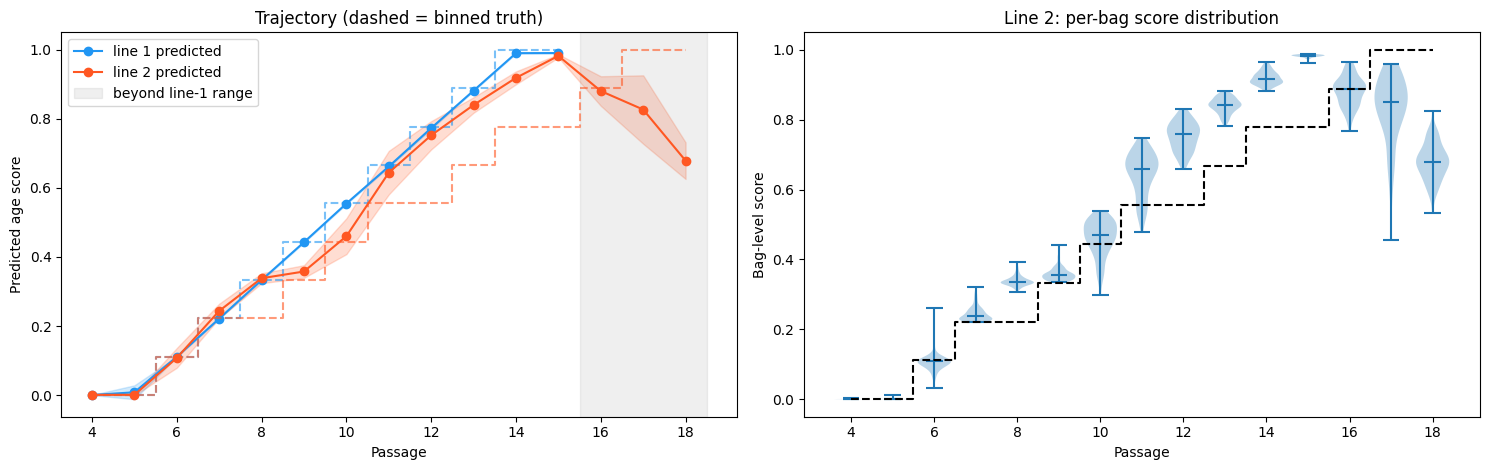

In [26]:
store = {}
for (line, p), idx in sorted(groups.items()):
    bags = sample_bags(idx, N_BAGS, SEED + 1000 * line + p)
    sc, at = run_bags(bags)
    store[(line, p)] = dict(idx=idx, bags=bags, scores=sc, attn=at)

rows = []
for (line, p), e in sorted(store.items()):
    m = meta.iloc[e["idx"]]
    rows.append(dict(line=line, passage=p, bin=int(m["bin"].iloc[0]), s_true=float(m["s_bin"].iloc[0]),
                     s_hat=e["scores"].mean(), s_sd=e["scores"].std(),
                     n_cells=len(e["idx"]), n_wells=m["well"].nunique()))
traj = pd.DataFrame(rows); traj["err"] = traj["s_hat"] - traj["s_true"]
traj.to_csv(OUT / "trajectory_binned.csv", index=False)
print(traj.round(4).to_string(index=False))

ho = traj[traj.line == HELD_OUT]
late_lbl = f"late (P{min(LATE)}-P{max(LATE)})"
seg = {f"P<{min(LATE)}": ho[~ho.passage.isin(LATE)], late_lbl: ho[ho.passage.isin(LATE)], "all held-out": ho}
summary = pd.DataFrame({k: dict(n=len(v), MAE_s=v.err.abs().mean(), bias=v.err.mean(),
                                spearman_vs_bin=spearmanr(v.s_true, v.s_hat)[0],
                                spearman_vs_passage=spearmanr(v.passage, v.s_hat)[0]) for k, v in seg.items()}).T
print("\nHeld-out line segments:"); print(summary.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for line in (TRAIN_LINE, HELD_OUT):
    d = traj[traj.line == line]
    ax[0].plot(d.passage, d.s_hat, "-o", color=COL[line], label=f"line {line} predicted")
    ax[0].fill_between(d.passage, d.s_hat - d.s_sd, d.s_hat + d.s_sd, color=COL[line], alpha=0.2)
    ax[0].step(d.passage, d.s_true, where="mid", color=COL[line], ls="--", alpha=0.6)
ax[0].axvspan(TRAIN_MAX + 0.5, traj.passage.max() + 0.5, color="grey", alpha=0.12, label="beyond line-1 range")
ax[0].set(xlabel="Passage", ylabel="Predicted age score", title="Trajectory (dashed = binned truth)"); ax[0].legend()
ps = sorted(p for (l, p) in store if l == HELD_OUT)
ax[1].violinplot([store[(HELD_OUT, p)]["scores"] for p in ps], positions=ps, showmedians=True, widths=0.8)
ax[1].step(ps, [traj[(traj.line == HELD_OUT) & (traj.passage == p)].s_true.iloc[0] for p in ps], where="mid", color="k", ls="--")
ax[1].set(xlabel="Passage", ylabel="Bag-level score", title=f"Line {HELD_OUT}: per-bag score distribution")
fig.tight_layout(); savefig(fig, "01_trajectory.png")

## Section 2: How does attention behave?
Attention weights sum to 1 per bag, so uniform attention is `1/N`. Normalised entropy of 1 means uniform; low entropy means attention is concentrated on few cells. `cell_attn` (used later) is each cell's mean attention divided by `1/N`, so 1.0 is average.

 line  passage  norm_entropy  top10pct_mass  eff_cell_frac  cells_seen
    1        4        0.9961         0.1316         0.9869      0.9931
    1        5        0.9964         0.1307         0.9877      0.9912
    1        6        0.9958         0.1327         0.9859      0.9144
    1        7        0.9956         0.1319         0.9851      1.0000
    1        8        0.9929         0.1445         0.9760      0.8096
    1        9        0.9901         0.1553         0.9668      0.9723
    1       10        0.9960         0.1308         0.9864      0.9577
    1       11        0.9952         0.1306         0.9837      0.9961
    1       12        0.9938         0.1370         0.9793      0.9978
    1       13        0.9967         0.1270         0.9890      1.0000
    1       14        0.9955         0.1335         0.9847      1.0000
    1       15        0.9943         0.1360         0.9807      1.0000
    2        4        0.9969         0.1278         0.9896      0.9977
    2 

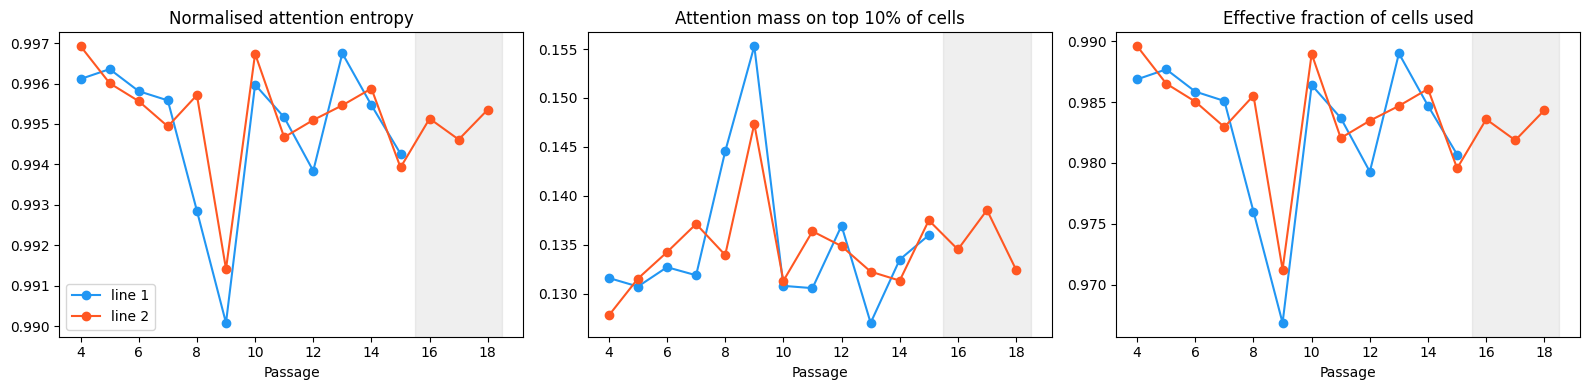

In [19]:
def attn_stats(a):
    a = np.clip(a, 1e-12, None); n = a.shape[1]
    ent = -(a * np.log(a)).sum(1)
    k = max(1, int(np.ceil(0.1 * n)))
    return ent.mean() / np.log(n), np.sort(a, 1)[:, -k:].sum(1).mean(), (np.exp(ent) / n).mean()

for key, e in store.items():
    pos = np.searchsorted(e["idx"], e["bags"].ravel())
    s = np.bincount(pos, weights=e["attn"].ravel(), minlength=len(e["idx"]))
    c = np.bincount(pos, minlength=len(e["idx"]))
    e["cell_attn"] = np.where(c > 0, s / np.maximum(c, 1), np.nan) * CPB     # relative attention, 1.0 = uniform

rows = []
for (line, p), e in sorted(store.items()):
    h, top, eff = attn_stats(e["attn"])
    rows.append(dict(line=line, passage=p, norm_entropy=h, top10pct_mass=top, eff_cell_frac=eff,
                     cells_seen=np.isfinite(e["cell_attn"]).mean()))
attn_df = pd.DataFrame(rows); attn_df.to_csv(OUT / "attention_concentration.csv", index=False)
print(attn_df.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for j, (col, ttl) in enumerate([("norm_entropy", "Normalised attention entropy"),
                                ("top10pct_mass", "Attention mass on top 10% of cells"),
                                ("eff_cell_frac", "Effective fraction of cells used")]):
    for line in (TRAIN_LINE, HELD_OUT):
        d = attn_df[attn_df.line == line]; ax[j].plot(d.passage, d[col], "-o", color=COL[line], label=f"line {line}")
    ax[j].axvspan(TRAIN_MAX + 0.5, attn_df.passage.max() + 0.5, color="grey", alpha=0.12)
    ax[j].set(xlabel="Passage", title=ttl)
ax[0].legend(); fig.tight_layout(); savefig(fig, "02_attention_concentration.png")

## Section 3: Which features does the model attend to, and how do they move with passage?
Focus features come from the run's integrated-gradients file (`*_importance_normalised.csv`) when it exists, otherwise the features most rank-correlated with age bin on the training line. Values are z-scores relative to line 1 (the scaler fit): 0 is the line-1 average cell.

The first figure shows attention-weighted mean z per passage (what the model emphasises). The third panel is attention-weighted minus plain mean: which features are over-represented among the cells the model attends to.

Focus features ( integrated gradients ): ['Area', 'ratio5', 'MinAxisLength', 'skew_2', 'MaxAxisLength', 'ratio4', 'kurt_40per_2', 'latent_15', 'Perimeter', 'ratio8', 'ratio6', 'kurt_10']


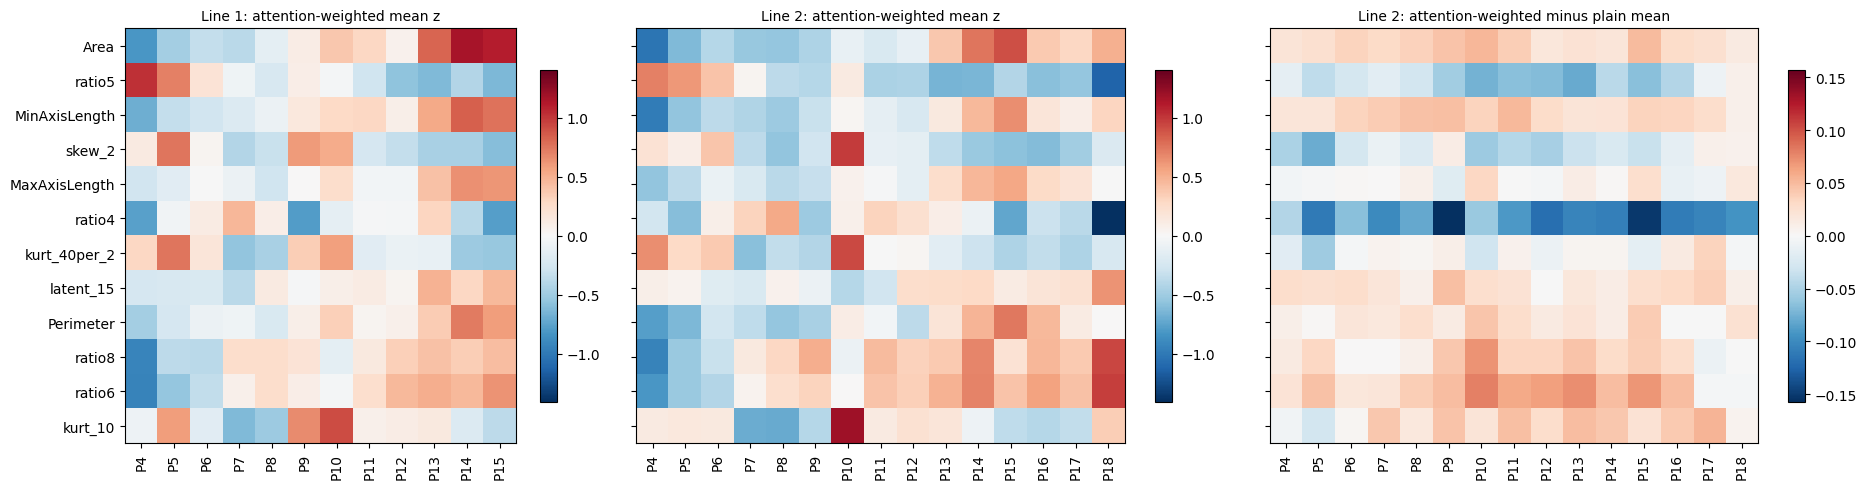

In [20]:
imp_path = LOG_DIR / f"{RUN_NAME}_importance_normalised.csv"
tr_cells = np.where((meta.line.values == TRAIN_LINE) & valid)[0]
if imp_path.exists():
    imp = pd.read_csv(imp_path)
    focus = [f for f in imp["feature"] if f in FEATS][:12]; focus_src = "integrated gradients"
else:
    rho = [abs(spearmanr(Z[tr_cells, j], meta.bin.values[tr_cells])[0]) for j in range(Z.shape[1])]
    focus = [FEATS[j] for j in np.argsort(rho)[::-1][:12]]; focus_src = f"|Spearman| with bin on line {TRAIN_LINE}"
fi = [FEATS.index(f) for f in focus]
print("Focus features (", focus_src, "):", focus)

def profile(key, weighted):
    e = store[key]; z = Z[e["idx"]][:, fi]
    if not weighted: return z.mean(0)
    w = np.nan_to_num(e["cell_attn"]); return (w[:, None] * z).sum(0) / w.sum()

def prof_df(line, weighted):
    ps = sorted(p for (l, p) in store if l == line)
    return pd.DataFrame({p: profile((line, p), weighted) for p in ps}, index=focus)

pw = {l: prof_df(l, True) for l in (TRAIN_LINE, HELD_OUT)}
pu = prof_df(HELD_OUT, False)
diff = pw[HELD_OUT] - pu
lim = float(np.nanmax(np.abs(np.concatenate([pw[TRAIN_LINE].values.ravel(), pw[HELD_OUT].values.ravel()]))))
fig, ax = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw=dict(width_ratios=[pw[TRAIN_LINE].shape[1], pw[HELD_OUT].shape[1], pw[HELD_OUT].shape[1]]))
for a, d, ttl, v in [(ax[0], pw[TRAIN_LINE], f"Line {TRAIN_LINE}: attention-weighted mean z", lim),
                     (ax[1], pw[HELD_OUT], f"Line {HELD_OUT}: attention-weighted mean z", lim),
                     (ax[2], diff, f"Line {HELD_OUT}: attention-weighted minus plain mean", max(np.abs(diff.values).max(), 1e-6))]:
    im = a.imshow(d.values, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
    a.set_xticks(range(d.shape[1])); a.set_xticklabels([f"P{c}" for c in d.columns], rotation=90)
    a.set_yticks(range(len(focus))); a.set_yticklabels(focus if a is ax[0] else [])
    a.set_title(ttl, fontsize=10); fig.colorbar(im, ax=a, shrink=0.8)
fig.tight_layout(); savefig(fig, "03_attended_feature_profile.png")
pd.concat({f"L{l}": pw[l] for l in pw}, axis=1).to_csv(OUT / "attention_weighted_feature_z.csv")

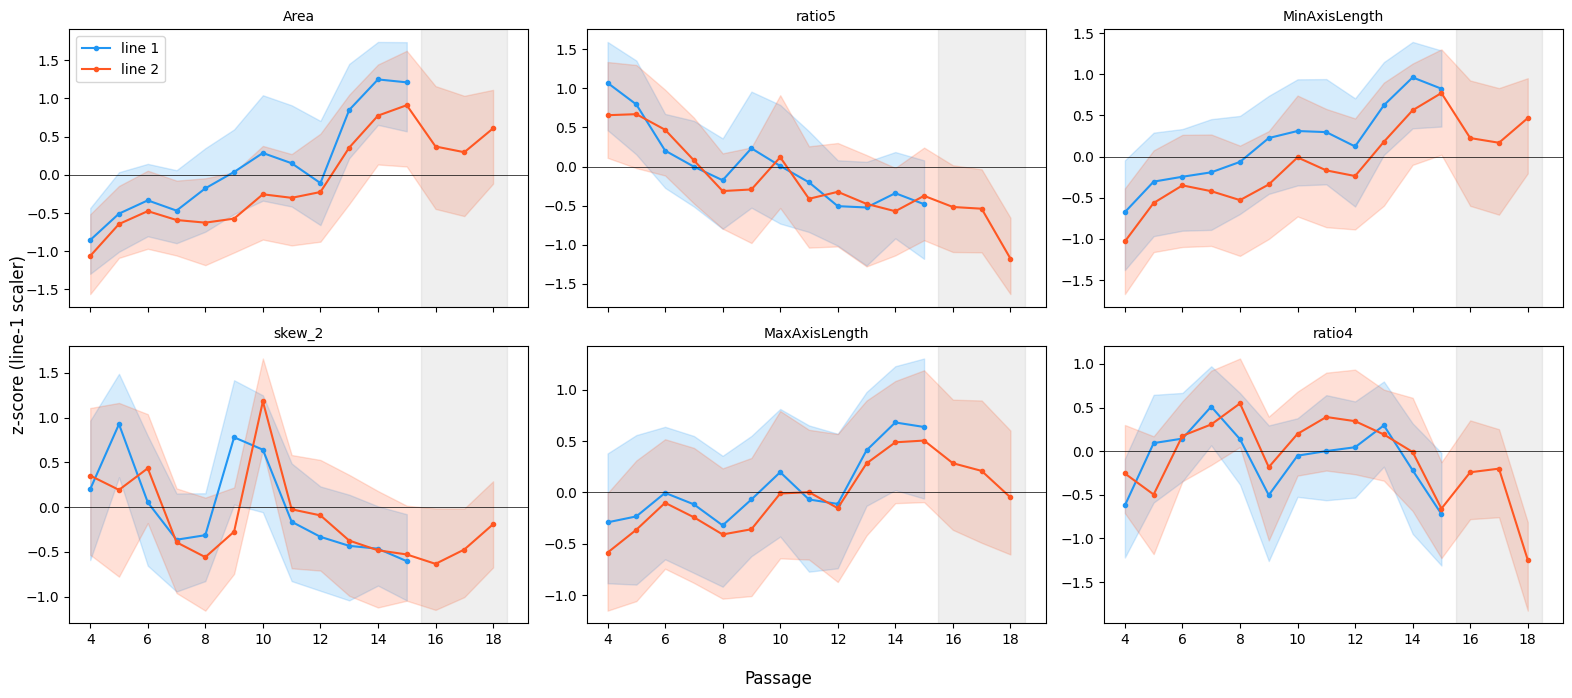

In [21]:
# Feature trajectories: median and IQR of z per passage, both lines
show = focus[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for a, f in zip(axes.ravel(), show):
    j = FEATS.index(f)
    for line in (TRAIN_LINE, HELD_OUT):
        ps = sorted(p for (l, p) in store if l == line)
        q = np.array([np.percentile(Z[store[(line, p)]["idx"], j], [25, 50, 75]) for p in ps])
        a.plot(ps, q[:, 1], "-o", ms=3, color=COL[line], label=f"line {line}")
        a.fill_between(ps, q[:, 0], q[:, 2], color=COL[line], alpha=0.18)
    a.axvspan(TRAIN_MAX + 0.5, max(ps) + 0.5, color="grey", alpha=0.12)
    a.axhline(0, color="k", lw=0.5); a.set_title(f, fontsize=10)
axes[0, 0].legend(); fig.supxlabel("Passage"); fig.supylabel("z-score (line-1 scaler)")
fig.tight_layout(); savefig(fig, "04_feature_trajectories.png")

## Section 4: H1, are P16–18 outside what line 1 can teach?
Two checks in the model's (block-weighted) feature space. `knn_dist` is the mean distance to the 5 nearest line-1 cells (line-1 groups exclude themselves). `frac_ge3_outside` is the fraction of cells with 3 or more features outside line 1's 0.5–99.5 percentile range. If late passages sit well above the P10–15 values, the model is extrapolating.

 line  passage  knn_dist  frac_any_absz_gt4  frac_ge3_outside
    1        4    3.9497             0.0069            0.1098
    1        5    3.8915             0.0080            0.0800
    1        6    3.8726             0.0100            0.0460
    1        7    3.9614             0.0113            0.0590
    1        8    3.9273             0.0180            0.0640
    1        9    4.0682             0.0240            0.1120
    1       10    3.9203             0.0160            0.0980
    1       11    3.9380             0.0120            0.0720
    1       12    3.8680             0.0067            0.0421
    1       13    3.8807             0.0111            0.0557
    1       14    3.8632             0.0152            0.0394
    1       15    3.8637             0.0150            0.0569
    2        4    3.9284             0.0117            0.1098
    2        5    3.9696             0.0160            0.1040
    2        6    3.8332             0.0120            0.0400
    2   

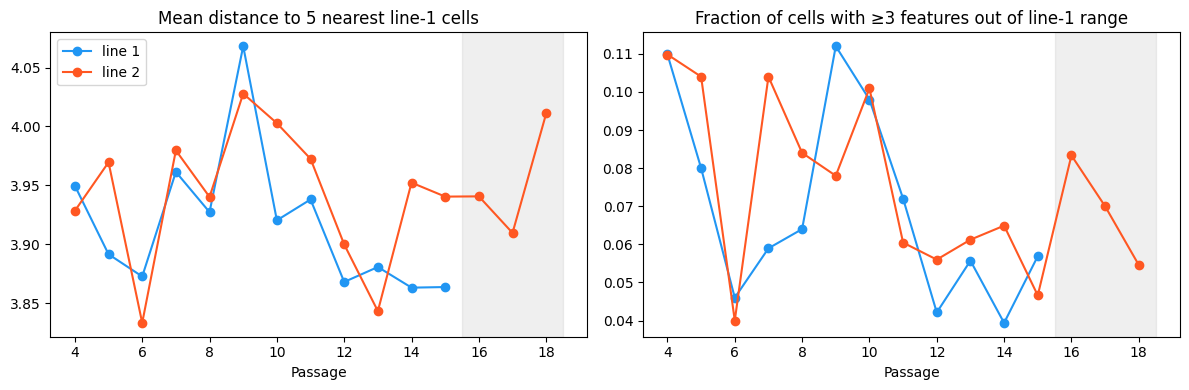

In [22]:
from sklearn.neighbors import NearestNeighbors
nn_idx = NearestNeighbors(n_neighbors=6).fit(X[tr_cells])
lo, hi = np.percentile(Z[tr_cells], [0.5, 99.5], axis=0)
rng = np.random.default_rng(SEED)
rows = []
for (line, p), e in sorted(store.items()):
    q = rng.choice(e["idx"], size=min(500, len(e["idx"])), replace=False)
    d, _ = nn_idx.kneighbors(X[q])
    d = d[:, 1:] if line == TRAIN_LINE else d[:, :5]
    outside = (Z[q] < lo) | (Z[q] > hi)
    rows.append(dict(line=line, passage=p, knn_dist=d.mean(), frac_any_absz_gt4=(np.abs(Z[q]) > 4).any(1).mean(),
                     frac_ge3_outside=(outside.sum(1) >= 3).mean()))
ood = pd.DataFrame(rows); ood.to_csv(OUT / "ood_metrics.csv", index=False)
print(ood.round(4).to_string(index=False))

late_idx = np.concatenate([groups[(HELD_OUT, p)] for p in LATE if (HELD_OUT, p) in groups])
mid_idx  = np.concatenate([groups[(HELD_OUT, p)] for p in MID if (HELD_OUT, p) in groups])
out_late = ((Z[late_idx] < lo) | (Z[late_idx] > hi)).mean(0)
out_mid  = ((Z[mid_idx]  < lo) | (Z[mid_idx]  > hi)).mean(0)
oor = pd.DataFrame({"feature": FEATS, "frac_outside_late": out_late, "frac_outside_mid": out_mid,
                    "excess": out_late - out_mid, "median_z_late": np.median(Z[late_idx], 0),
                    "median_z_mid": np.median(Z[mid_idx], 0)}).sort_values("excess", ascending=False)
print("\nFeatures most out-of-range in late passages (vs P10-15 on the held-out line):")
print(oor.head(12).round(3).to_string(index=False))
oor.to_csv(OUT / "out_of_range_features.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, (col, ttl) in enumerate([("knn_dist", "Mean distance to 5 nearest line-1 cells"),
                                ("frac_ge3_outside", "Fraction of cells with ≥3 features out of line-1 range")]):
    for line in (TRAIN_LINE, HELD_OUT):
        d = ood[ood.line == line]; ax[j].plot(d.passage, d[col], "-o", color=COL[line], label=f"line {line}")
    ax[j].axvspan(TRAIN_MAX + 0.5, ood.passage.max() + 0.5, color="grey", alpha=0.12); ax[j].set(xlabel="Passage", title=ttl)
ax[0].legend(); fig.tight_layout(); savefig(fig, "05_ood.png")

## Section 5: H2, is it driven by particular wells?
Bags are built from **one well at a time** (wells with ≥40 cells, 30 bags each). If all late-passage wells score low, the effect is consistent across wells. If one or two wells are low and the rest are near P15, a well or plate effect is likely.

 line  passage  n_wells   mean  between_well_sd    min    max
    1        4        5 0.0004           0.0002 0.0002 0.0007
    1        5        6 0.0412           0.0674 0.0009 0.1771
    1        6        6 0.1284           0.0413 0.1097 0.2125
    1        7        5 0.2220           0.0025 0.2190 0.2260
    1        8        6 0.3370           0.0101 0.3286 0.3570
    1        9        5 0.4707           0.0242 0.4437 0.4983
    1       10        6 0.5714           0.0437 0.5434 0.6592
    1       11        6 0.6619           0.0055 0.6564 0.6723
    1       12        6 0.7686           0.0119 0.7459 0.7791
    1       13        6 0.8801           0.0028 0.8757 0.8838
    1       14        4 0.9780           0.0109 0.9651 0.9874
    1       15        6 0.9878           0.0011 0.9861 0.9890
    2        4        5 0.0010           0.0008 0.0002 0.0023
    2        5        4 0.0014           0.0017 0.0002 0.0039
    2        6        6 0.1402           0.1180 0.0288 0.3685
    2   

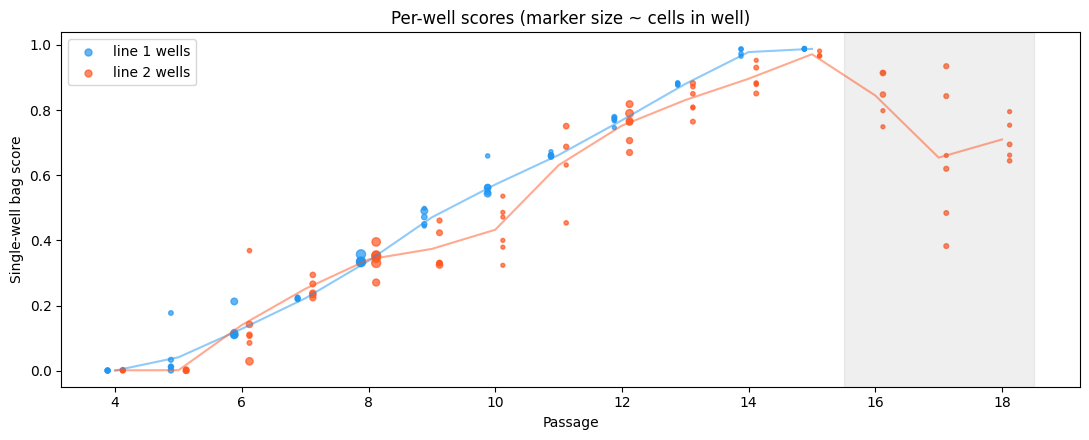

In [9]:
rows = []
for (line, p), e in sorted(store.items()):
    idx = e["idx"]; w = wells_of[idx]
    for u in np.unique(w):
        iw = idx[w == u]
        if len(iw) < 40: continue
        sc, _ = run_bags(sample_bags(iw, 30, SEED + 7 * p + line, mwf=1.0))
        rows.append(dict(line=line, passage=p, well=str(u), n_cells=len(iw), well_score=sc.mean(), well_sd=sc.std()))
well_df = pd.DataFrame(rows); well_df.to_csv(OUT / "well_level_scores.csv", index=False)

wsum = (well_df.groupby(["line", "passage"]).agg(n_wells=("well", "size"), mean=("well_score", "mean"),
        between_well_sd=("well_score", "std"), min=("well_score", "min"), max=("well_score", "max")).reset_index())
print(wsum.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4.5))
for line in (TRAIN_LINE, HELD_OUT):
    d = well_df[well_df.line == line]
    ax.scatter(d.passage + (0.12 if line == HELD_OUT else -0.12), d.well_score, s=np.clip(d.n_cells / 8, 8, 80),
               color=COL[line], alpha=0.7, label=f"line {line} wells")
    m = d.groupby("passage").well_score.mean(); ax.plot(m.index, m.values, "-", color=COL[line], alpha=0.5)
ax.axvspan(TRAIN_MAX + 0.5, well_df.passage.max() + 0.5, color="grey", alpha=0.12)
ax.set(xlabel="Passage", ylabel="Single-well bag score", title="Per-well scores (marker size ~ cells in well)"); ax.legend()
fig.tight_layout(); savefig(fig, "06_well_scores.png")

## Section 6: H3, which features pull the score down?
**Knock-out test.** Set one feature (or a whole block) to 0 (the line-1 mean after scaling) for every cell in 50 bags and record the change in predicted score. A **positive** change at P17 means that feature was pulling the P17 score *down*; removing it lets the score recover.

**Gradient decomposition.** First-order estimate of the score change between P15 and each late passage: `Δs ≈ Σ_f ḡ_f · Δx̄_f`, where `ḡ` is the mean input gradient (average over the two groups' bags) and `Δx̄` the difference in mean block-weighted features. The printed sum should be close to the actual change. If it is not, the relationship is non-linear (attention or head interactions) and the decomposition is only indicative.

Baseline scores: {'P13': 0.837, 'P15': 0.983, 'P16': 0.877, 'P17': 0.835, 'P18': 0.677}

Δ score when a feature is knocked out (positive = feature was lowering the score):
                P13    P15    P16    P17    P18
ratio4        0.012 -0.009 -0.011 -0.083  0.205
rawIntDen_1   0.005  0.001  0.004  0.023  0.174
ratio5        0.034  0.002  0.048 -0.006 -0.124
latent_15    -0.001 -0.001 -0.001  0.010 -0.112
Area         -0.036 -0.065 -0.072 -0.103 -0.079
mean_1        0.002  0.000  0.002  0.004  0.102
rawIntDen_14  0.007 -0.000  0.008  0.023  0.092
rawIntDen_12 -0.012 -0.005 -0.016 -0.090 -0.083
skew_1        0.003 -0.003 -0.009 -0.086 -0.017
skew_2       -0.016 -0.012 -0.037 -0.072 -0.031
rawIntDen_13  0.011  0.002  0.019  0.069 -0.022
mean_3       -0.001 -0.001 -0.003 -0.007  0.066
ratio6        0.029 -0.002  0.053  0.047  0.062
mean_14      -0.013 -0.001 -0.009 -0.019  0.052
var_20per_5  -0.001 -0.001 -0.022 -0.012 -0.051

Block knock-out Δ score:
          P13    P15    P16    P17

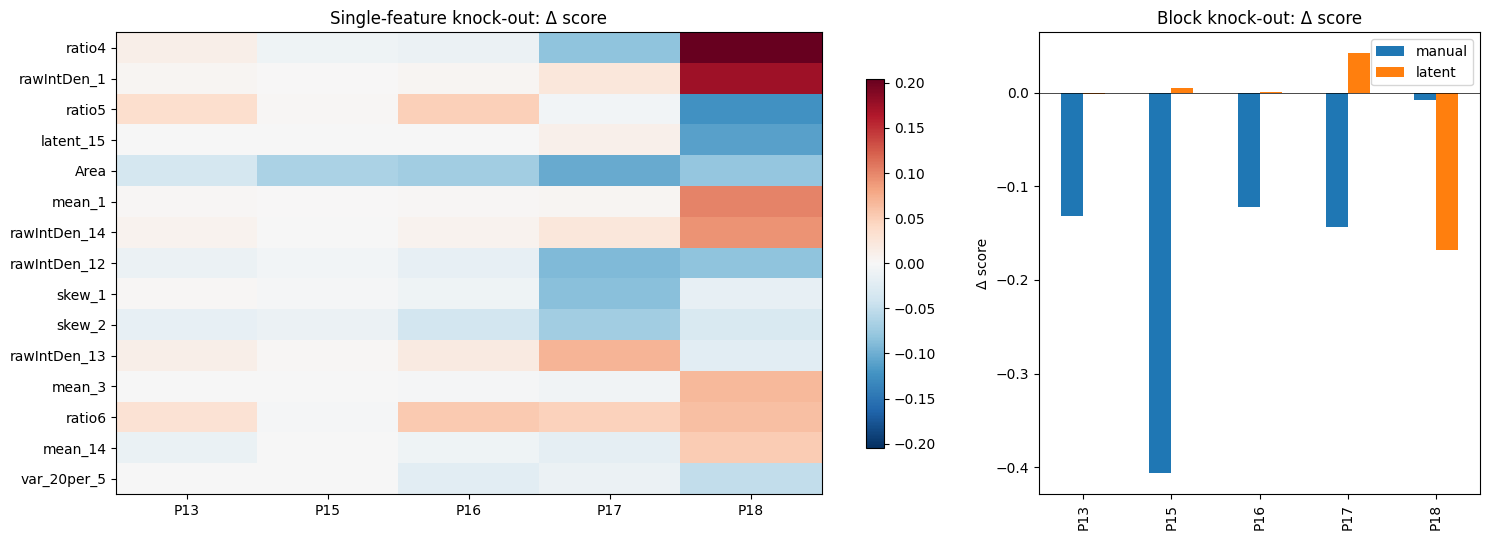

In [10]:
ABL = [(HELD_OUT, p) for p in [13, 15] + LATE if (HELD_OUT, p) in store]
NB = 50
def ablate(key, cols):
    bag = X[store[key]["bags"][:NB]].astype(np.float32)
    if cols is not None: bag[:, :, cols] = 0.0
    lg, _ = model_forward(np.ascontiguousarray(bag)); return np_score(lg).mean()

base = {k: ablate(k, None) for k in ABL}
delta = pd.DataFrame({f"P{k[1]}": [ablate(k, [j]) - base[k] for j in range(len(FEATS))] for k in ABL}, index=FEATS)
late_cols = [f"P{p}" for p in LATE if f"P{p}" in delta.columns]
rank_feats = delta[late_cols].abs().max(axis=1).sort_values(ascending=False).index[:15]
print("Baseline scores:", {f"P{k[1]}": round(float(v), 3) for k, v in base.items()})
print("\nΔ score when a feature is knocked out (positive = feature was lowering the score):")
print(delta.loc[rank_feats].round(3).to_string())

blocks = {"manual": list(range(N_MAN)), "latent": list(range(N_MAN, len(FEATS)))}
blk = pd.DataFrame({f"P{k[1]}": {b: ablate(k, c) - base[k] for b, c in blocks.items() if c} for k in ABL})
print("\nBlock knock-out Δ score:"); print(blk.round(3).to_string())
delta.to_csv(OUT / "feature_knockout_delta.csv"); blk.to_csv(OUT / "block_knockout_delta.csv")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[2, 1]))
d = delta.loc[rank_feats]; v = max(np.abs(d.values).max(), 1e-6)
im = ax[0].imshow(d.values, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
ax[0].set_xticks(range(d.shape[1])); ax[0].set_xticklabels(d.columns); ax[0].set_yticks(range(len(d))); ax[0].set_yticklabels(d.index)
ax[0].set_title("Single-feature knock-out: Δ score"); fig.colorbar(im, ax=ax[0], shrink=0.8)
blk.T.plot.bar(ax=ax[1]); ax[1].axhline(0, color="k", lw=0.5); ax[1].set_title("Block knock-out: Δ score"); ax[1].set_ylabel("Δ score")
fig.tight_layout(); savefig(fig, "07_knockouts.png")

Score change relative to P15 and its first-order decomposition:
 passage  actual_delta  first_order_sum  manual_part  latent_part
      16        -0.102           -0.001       -0.001        0.000
      17        -0.155           -0.002       -0.003        0.001
      18        -0.303           -0.003       -0.004        0.001

Top per-feature contributions (negative = pulls the score down vs P15):
                 P16    P17    P18
Area          -0.001 -0.001 -0.000
rawIntDen_1    0.000 -0.000 -0.001
latent_15      0.000 -0.000  0.001
Perimeter     -0.000 -0.001 -0.000
mean_1        -0.000 -0.000 -0.001
ratio4        -0.000 -0.000 -0.000
ratio5        -0.000 -0.000  0.000
MinAxisLength -0.000 -0.000 -0.000
rawIntDen_12  -0.000  0.000  0.000
skew_4         0.000  0.000 -0.000
skew_2         0.000 -0.000 -0.000
MaxAxisLength -0.000 -0.000 -0.000
rawIntDen_14  -0.000 -0.000 -0.000
mean_3        -0.000 -0.000 -0.000
mean_14        0.000  0.000 -0.000


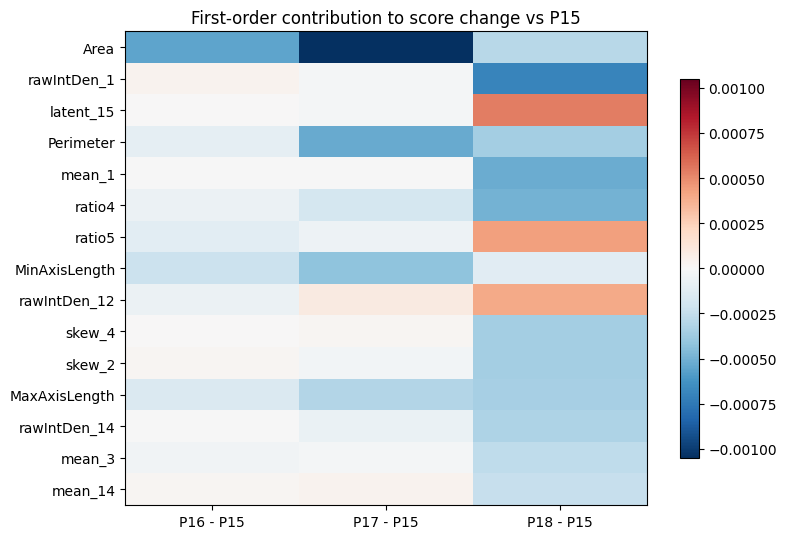

In [11]:
def mean_grad(key, nb=30):
    return model_input_grad(np.ascontiguousarray(X[store[key]["bags"][:nb]], dtype=np.float32)).mean(axis=(0, 1))
REF = (HELD_OUT, 15)
gref, xref = mean_grad(REF), X[store[REF]["idx"]].mean(0)
contrib, decomp_rows = {}, []
for p in LATE:
    k = (HELD_OUT, p)
    g = 0.5 * (gref + mean_grad(k)); dx = X[store[k]["idx"]].mean(0) - xref
    c = g * dx
    contrib[f"P{p}"] = pd.Series(c, index=FEATS)
    actual = store[k]["scores"].mean() - store[REF]["scores"].mean()
    decomp_rows.append(dict(passage=p, actual_delta=actual, first_order_sum=c.sum(),
                            manual_part=c[:N_MAN].sum(), latent_part=c[N_MAN:].sum()))
decomp = pd.DataFrame(decomp_rows); contrib = pd.DataFrame(contrib)
print("Score change relative to P15 and its first-order decomposition:"); print(decomp.round(3).to_string(index=False))
top = contrib.abs().max(axis=1).sort_values(ascending=False).index[:15]
print("\nTop per-feature contributions (negative = pulls the score down vs P15):"); print(contrib.loc[top].round(3).to_string())
contrib.to_csv(OUT / "gradient_decomposition.csv"); decomp.to_csv(OUT / "gradient_decomposition_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
d = contrib.loc[top]; v = max(np.abs(d.values).max(), 1e-6)
im = ax.imshow(d.values, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
ax.set_xticks(range(d.shape[1])); ax.set_xticklabels([f"{c} - P15" for c in d.columns]); ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
ax.set_title("First-order contribution to score change vs P15"); fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); savefig(fig, "08_gradient_decomposition.png")

## Section 7: H4, does the score depend on which cells are attended?
For each held-out passage, bags are built only from the **top 25%** or **bottom 25%** most-attended cells (by mean attention over the 100 bags above), plus a random 25% control of the same size. If top-attention cells score highest at P15 but the pattern changes at P16–18 (for example the top-attended cells now score lowest), the model is attending to cells that look young at late passages. Subsets with fewer than 100 cells are resampled with replacement.

 passage  all_cells  top25_attn  bottom25_attn  random25  top_minus_bottom  s_true
       4      0.001       0.013          0.004     0.001             0.009   0.000
       5      0.001       0.135          0.005     0.000             0.130   0.000
       6      0.108       0.211          0.134     0.105             0.077   0.111
       7      0.244       0.470          0.245     0.244             0.224   0.222
       8      0.338       0.512          0.242     0.355             0.270   0.222
       9      0.358       0.475          0.257     0.340             0.218   0.333
      10      0.460       0.572          0.115     0.495             0.457   0.444
      11      0.644       0.771          0.238     0.632             0.533   0.556
      12      0.752       0.777          0.419     0.781             0.358   0.556
      13      0.840       0.778          0.631     0.815             0.147   0.667
      14      0.919       0.848          0.770     0.930             0.078   0.778
    

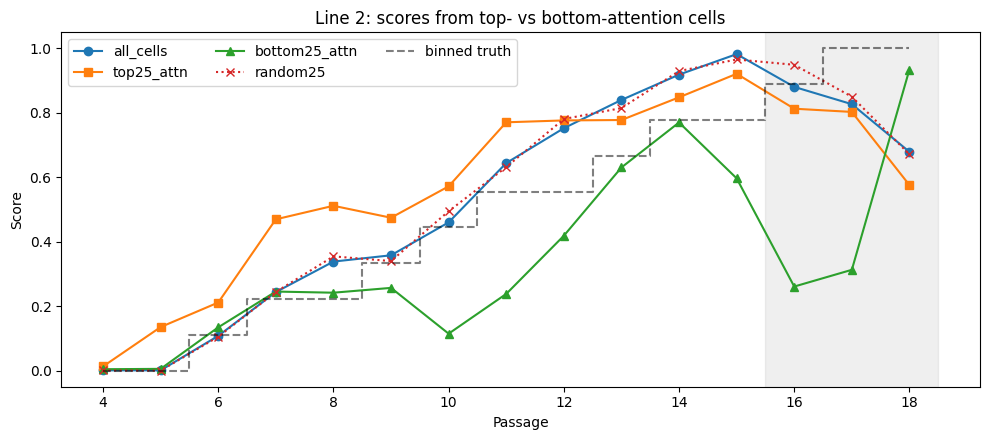

In [12]:
def subset_scores(key, q_lo, q_hi, seed):
    e = store[key]; ca = e["cell_attn"]; ok = np.isfinite(ca)
    lo_, hi_ = np.nanquantile(ca, [q_lo, q_hi])
    sel = e["idx"][ok & (ca >= lo_) & (ca <= hi_)]
    sc, _ = run_bags(sample_bags(sel, 30, seed, mwf=1.0)); return sc.mean(), sel
rows = []
for p in sorted(p for (l, p) in store if l == HELD_OUT):
    k = (HELD_OUT, p)
    top_s, sel = subset_scores(k, 0.75, 1.0, SEED + p)
    bot_s, _   = subset_scores(k, 0.0, 0.25, SEED + p)
    rnd = np.random.default_rng(SEED + p).choice(store[k]["idx"], size=len(sel), replace=False)
    rnd_s, _ = run_bags(sample_bags(rnd, 30, SEED + p, mwf=1.0))
    rows.append(dict(passage=p, all_cells=store[k]["scores"].mean(), top25_attn=top_s, bottom25_attn=bot_s,
                     random25=rnd_s.mean(), top_minus_bottom=top_s - bot_s,
                     s_true=float(meta.s_bin.values[store[k]["idx"][0]])))
sub = pd.DataFrame(rows); sub.to_csv(OUT / "attention_subset_scores.csv", index=False)
print(sub.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, st in [("all_cells", "-o"), ("top25_attn", "-s"), ("bottom25_attn", "-^"), ("random25", ":x")]:
    ax.plot(sub.passage, sub[col], st, label=col)
ax.step(sub.passage, sub.s_true, where="mid", color="k", ls="--", alpha=0.5, label="binned truth")
ax.axvspan(TRAIN_MAX + 0.5, sub.passage.max() + 0.5, color="grey", alpha=0.12)
ax.set(xlabel="Passage", ylabel="Score", title=f"Line {HELD_OUT}: scores from top- vs bottom-attention cells"); ax.legend(ncol=3)
fig.tight_layout(); savefig(fig, "09_attention_subsets.png")

## Section 8: Scorecard
Late passages compared with P10–15 on the held-out line. A large change in a row is evidence for the corresponding hypothesis; the last column says what that change would mean. Treat these as pointers for follow-up, not proof.

In [13]:
def seg_mean(df, col, ps, **flt):
    d = df[df.passage.isin(ps)]
    for k, v in flt.items(): d = d[d[k] == v]
    return d[col].mean()

err_h = traj[traj.line == HELD_OUT]
sub_l, sub_m = sub[sub.passage.isin(LATE)], sub[sub.passage.isin(MID)]
card = pd.DataFrame([
    ("score error vs bin (mean |err|)", err_h[err_h.passage.isin(MID)].err.abs().mean(), err_h[err_h.passage.isin(LATE)].err.abs().mean(), "the failure itself"),
    ("H1 kNN distance to line-1 cells", seg_mean(ood, "knn_dist", MID, line=HELD_OUT), seg_mean(ood, "knn_dist", LATE, line=HELD_OUT), "higher: extrapolation beyond line 1"),
    ("H1 frac. cells with ≥3 features out of range", seg_mean(ood, "frac_ge3_outside", MID, line=HELD_OUT), seg_mean(ood, "frac_ge3_outside", LATE, line=HELD_OUT), "higher: line 1 cannot cover these cells"),
    ("H2 between-well SD of well score", seg_mean(wsum, "between_well_sd", MID, line=HELD_OUT), seg_mean(wsum, "between_well_sd", LATE, line=HELD_OUT), "higher: well/plate heterogeneity"),
    ("H4 normalised attention entropy", seg_mean(attn_df, "norm_entropy", MID, line=HELD_OUT), seg_mean(attn_df, "norm_entropy", LATE, line=HELD_OUT), "change: attention more diffuse/focused"),
    ("H4 top-minus-bottom attention score gap", sub_m.top_minus_bottom.mean(), sub_l.top_minus_bottom.mean(), "sign flip: attended cells look young"),
], columns=["metric", "P10-15", "late", "reading if changed"])
card["change"] = card["late"] - card["P10-15"]
print(card.round(4).to_string(index=False))
print("\nGradient decomposition vs P15: " + "; ".join(f"P{r.passage}: actual {r.actual_delta:+.3f}, first-order {r.first_order_sum:+.3f}" for r in decomp.itertuples()))
card.to_csv(OUT / "scorecard.csv", index=False)
print(f"\nTables saved to {OUT}\nFigures saved to {FIG}")

                                      metric  P10-15   late                      reading if changed  change
             score error vs bin (mean |err|)  0.1367 0.1674                      the failure itself  0.0307
             H1 kNN distance to line-1 cells  3.9352 3.9538     higher: extrapolation beyond line 1  0.0186
H1 frac. cells with ≥3 features out of range  0.0650 0.0693 higher: line 1 cannot cover these cells  0.0043
            H2 between-well SD of well score  0.0587 0.1149        higher: well/plate heterogeneity  0.0562
             H4 normalised attention entropy  0.9937 0.9932  change: attention more diffuse/focused -0.0005
     H4 top-minus-bottom attention score gap  0.3163 0.2278    sign flip: attended cells look young -0.0885

Gradient decomposition vs P15: P16: actual -0.102, first-order -0.001; P17: actual -0.155, first-order -0.002; P18: actual -0.303, first-order -0.003

Tables saved to C:\Users\goofy\PycharmProjects\MILAgeScore\outputs\loco_binned_HO_L2\logs\lo

## Reading the results

- **H1 supported** (kNN distance and out-of-range fraction jump at P16–18, and `out_of_range_features.csv` lists a few size or shape features): the model is extrapolating beyond line 1, and a line-1-only model cannot be expected to place these cells. A reverse run (train on line 2, hold out line 1) or training on both lines shows whether line 2's late passages carry a learnable phenotype.
- **H2 supported** (large between-well SD, one or two low wells): check those wells (seeding date, plate, imaging session) before interpreting the drop biologically.
- **H3 supported** (a few features dominate the knock-out and gradient tables, and their trajectories in section 3 reverse after P15): that is the morphological reason for the fall, and the most interpretable result. Check it against the biology (for example whether cells enlarge, flatten or detach after deep senescence).
- **H4 supported** (attention concentration changes, or top-attention cells score below bottom-attention cells at late passages): the aggregator is attending to cells that look young. Report attention alongside the score.
- If none of H1–H4 explains it, the next steps are the reverse LOCO run and a cell-level inspection of P17 images.